In [ ]:
import time, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

sebelumnya = globals().get('prob')     # gradient boosting data penuh dari sel model pertama, kalau masih ada

ROOT = Path('/content/drive/MyDrive/Logika Ui')
HASIL = ROOT / 'KTI_KARHUTLA' / 'hasil'
gadm2 = gpd.read_file(ROOT / 'GADM 2' / 'gadm41_IDN_2.shp')
TAU = 0.05
SUB = 300_000          # baris latih per lipatan, SAMA untuk semua model

tabel = pd.read_csv(HASIL / 'tabel_gabungan_nasional_semua_bulan.csv', parse_dates=['tanggal'])
pusat = gadm2.to_crs('EPSG:6933').geometry.centroid.to_crs('EPSG:4326')
koor = pd.DataFrame({'GID_2': gadm2['GID_2'].values, 'lat': pusat.y.values, 'lon': pusat.x.values})
tabel = tabel.merge(koor, on='GID_2', how='left')
hari = tabel['tanggal'].dt.dayofyear
tabel['doy_sin'] = np.sin(2 * np.pi * hari / 365.25)
tabel['doy_cos'] = np.cos(2 * np.pi * hari / 365.25)
curah = tabel['hujan_rata'] * 6
tabel['kelas'] = np.where(curah >= 1, 2, np.where(tabel['frac_hujan'] >= TAU, 1, 0))

fitur_dasar = ['lat', 'lon', 'doy_sin', 'doy_cos']
fitur_era_00 = [c for c in tabel.columns if c.endswith('_00')]
fitur_him = [c for c in tabel.columns if c.startswith('him_') and c not in ('him_n', 'him_f5')]
kC, kD = 'C prakiraan (00 UTC)', 'D pemantauan (00 UTC + awan)'
set_fitur = {kC: fitur_dasar + fitur_era_00, kD: fitur_dasar + fitur_era_00 + fitur_him}

n = len(tabel)
kelas = tabel['kelas'].to_numpy()
Y = np.eye(3)[kelas]
tahun = tabel['tahun'].to_numpy()
tahun_unik = np.unique(tahun)

# baris latih per lipatan: dipilih sekali, dipakai semua model dan kedua set fitur
rng = np.random.default_rng(1)
latih_per_th = {}
for th in tahun_unik:
    idx = np.flatnonzero(tahun != th)
    latih_per_th[th] = rng.choice(idx, SUB, replace=False) if len(idx) > SUB else idx
print(tabel.shape, '| baris latih per lipatan:', {int(k): len(v) for k, v in latih_per_th.items()})

def buat_model():
    return {
        'logistik': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                  LogisticRegression(C=0.1, max_iter=300)),
        'random forest': make_pipeline(SimpleImputer(strategy='median'),
                                       RandomForestClassifier(n_estimators=100, min_samples_leaf=20,
                                                              max_features='sqrt', n_jobs=-1,
                                                              random_state=1)),
        'gradient boosting': HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05,
                                                            max_iter=250, l2_regularization=1.0,
                                                            early_stopping=False, random_state=1),
    }

def klim_kelas(latih, uji):
    peta = (pd.get_dummies(latih['kelas']).astype(float)
            .assign(GID_2=latih['GID_2'].values, bulan=latih['bulan'].values)
            .groupby(['GID_2', 'bulan']).mean().reset_index())
    P = uji[['GID_2', 'bulan']].merge(peta, on=['GID_2', 'bulan'], how='left')[[0, 1, 2]]
    rata = latih['kelas'].value_counts(normalize=True).sort_index()
    return P.fillna(pd.Series(rata.to_numpy(), index=[0, 1, 2])).to_numpy()

prob = {'klimatologi': np.zeros((n, 3))}
for th in tahun_unik:
    prob['klimatologi'][tahun == th] = klim_kelas(tabel[tahun != th], tabel[tahun == th])   # klimatologi pakai semua baris

for nama_set, kolom in set_fitur.items():
    for nama, model in buat_model().items():
        kunci = f'{nama_set} | {nama}'
        prob[kunci] = np.zeros((n, 3))
        for th in tahun_unik:
            t0 = time.time()
            latih = latih_per_th[th]
            model.fit(tabel.iloc[latih][kolom], kelas[latih])
            uji = tahun == th
            prob[kunci][uji] = model.predict_proba(tabel.loc[uji, kolom])
            print(kunci, '| uji tahun', th, '|', round(time.time() - t0), 'dtk', flush=True)

def brier3(P, m):
    P = np.clip(P[m], 1e-6, 1)
    P = P / P.sum(axis=1, keepdims=True)
    return ((P - Y[m]) ** 2).sum(axis=1).mean()

def skill(P, m):
    return 1 - brier3(P, m) / brier3(prob['klimatologi'], m)

ada_awan = tabel['him_n'].notna().to_numpy()
semua = np.ones(n, bool)
sumatera = (tabel['NAME_1'].isin(['Riau', 'Jambi', 'Sumatera Selatan']) & tabel['bulan'].between(6, 10)).to_numpy()

daftar = []
for nama in ['logistik', 'random forest', 'gradient boosting']:
    PC = prob[f'{kC} | {nama}']
    PD = prob[f'{kD} | {nama}'].copy()
    PD[~ada_awan] = PC[~ada_awan]          # cadangan C kalau awan Himawari kosong
    daftar.append((nama, 'C prakiraan', PC))
    daftar.append((nama, 'D pemantauan (cadangan C)', PD))

if sebelumnya is not None and kC in sebelumnya and kD in sebelumnya and len(sebelumnya[kC]) == n:
    PCf = sebelumnya[kC]
    PDf = sebelumnya[kD].copy()
    PDf[~ada_awan] = PCf[~ada_awan]
    daftar.append(('gradient boosting (data penuh, pembanding)', 'C prakiraan', PCf))
    daftar.append(('gradient boosting (data penuh, pembanding)', 'D pemantauan (cadangan C)', PDf))

baris = []
for nama, lab, P in daftar:
    Pn = np.clip(P, 1e-6, 1)
    Pn = Pn / Pn.sum(axis=1, keepdims=True)
    baris.append({'model': nama, 'set fitur': lab,
                  'skill_semua': skill(P, semua),
                  'skill_Sumatera_JunOkt': skill(P, sumatera),
                  'brier_K1': brier_score_loss(kelas == 1, Pn[:, 1]),
                  'auc_K1': roc_auc_score(kelas == 1, Pn[:, 1]),
                  'log_loss': log_loss(kelas, Pn, labels=[0, 1, 2])})
ringkas = pd.DataFrame(baris).set_index(['model', 'set fitur']).round(4).sort_values('skill_semua', ascending=False)
print('\nPERBANDINGAN MODEL (skill 3 kelas terhadap klimatologi, validasi per tahun, baris latih sama)')
print(ringkas.to_string())
print('\npembanding v2 khusus Sumatera Jun-Okt: C 0,1685 | D cadangan 0,2412')

print('\nSKILL PER TAHUN UJI (konsistensi antar-lipatan)')
tab = {(nama, lab): {int(th): round(skill(P, tahun == th), 3) for th in tahun_unik} for nama, lab, P in daftar}
print(pd.DataFrame(tab).T.to_string())

nama_kunci = list(prob.keys())
np.savez_compressed(HASIL / 'prob_oof_nasional.npz', nama=np.array(nama_kunci),
                    **{f'm{i}': prob[k] for i, k in enumerate(nama_kunci)})
print('\ntersimpan: prob_oof_nasional.npz')

(1187441, 82) | baris latih per lipatan: {2020: 300000, 2021: 300000, 2022: 300000, 2023: 300000, 2024: 300000, 2025: 300000, 2026: 300000}
C prakiraan (00 UTC) | logistik | uji tahun 2020 | 15 dtk
C prakiraan (00 UTC) | logistik | uji tahun 2021 | 17 dtk
C prakiraan (00 UTC) | logistik | uji tahun 2022 | 17 dtk
C prakiraan (00 UTC) | logistik | uji tahun 2023 | 14 dtk
C prakiraan (00 UTC) | logistik | uji tahun 2024 | 17 dtk
C prakiraan (00 UTC) | logistik | uji tahun 2025 | 23 dtk
C prakiraan (00 UTC) | logistik | uji tahun 2026 | 12 dtk
C prakiraan (00 UTC) | random forest | uji tahun 2020 | 305 dtk
C prakiraan (00 UTC) | random forest | uji tahun 2021 | 334 dtk
C prakiraan (00 UTC) | random forest | uji tahun 2022 | 301 dtk
C prakiraan (00 UTC) | random forest | uji tahun 2023 | 311 dtk
C prakiraan (00 UTC) | random forest | uji tahun 2024 | 306 dtk
C prakiraan (00 UTC) | random forest | uji tahun 2025 | 308 dtk
C prakiraan (00 UTC) | random forest | uji tahun 2026 | 302 dtk
C prak

Mounted at /content/drive
K1 sebelum kalibrasi | brier 0.1733 | auc 0.7058
K1 sesudah kalibrasi | brier 0.1735 | auc 0.7048
skill 3 kelas        | sebelum 0.2109 | sesudah 0.2103
   sebelum         sesudah       
  prediksi amatan prediksi amatan
0    0.023  0.033    0.030  0.038
1    0.096  0.092    0.093  0.089
2    0.158  0.153    0.153  0.154
3    0.203  0.202    0.203  0.202
4    0.243  0.243    0.244  0.243
5    0.279  0.284    0.285  0.286
6    0.315  0.324    0.323  0.325
7    0.353  0.362    0.362  0.361
8    0.401  0.411    0.411  0.409
9    0.488  0.493    0.493  0.492


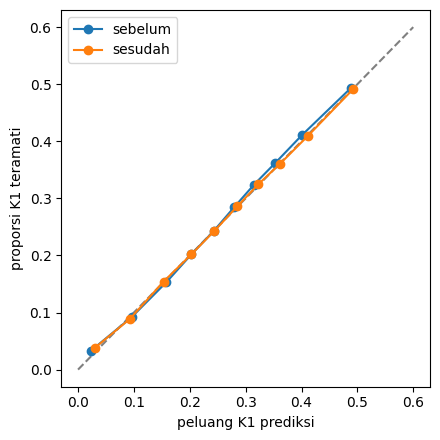

       baris   skill
1   103943.0  0.1948
2    94842.0  0.1555
3   103943.0  0.1352
4   100590.0  0.1737
5   103943.0  0.1987
6   100590.0  0.1993
7   103943.0  0.2502
8   103943.0  0.2779
9   100590.0  0.2866
10   95800.0  0.3008
11   86220.0  0.1932
12   89094.0  0.1718
                       baris   skill  auc_K1
Papua                71891.0  0.1396  0.6716
Sumatera Barat       42143.0  0.1443  0.6472
Sumatera Utara       76849.0  0.1443  0.6316
Sumatera Selatan     37185.0  0.1641  0.6477
Jambi                27269.0  0.1734  0.6460
Kalimantan Timur     22311.0  0.1788  0.6768
Sulawesi Selatan     59496.0  0.1797  0.6817
Kalimantan Barat     34706.0  0.1799  0.6677
Kepulauan Riau       17353.0  0.1839  0.6474
Bengkulu             24790.0  0.1847  0.6240
Kalimantan Utara     12395.0  0.1849  0.6928
Jakarta Raya          7437.0  0.1876  0.6843
Sulawesi Tengah      27269.0  0.1878  0.6742
Riau                 29748.0  0.1894  0.6560
Aceh                 57017.0  0.1970  0.6506
Banten 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
ROOT = Path('/content/drive/MyDrive/Logika Ui')
HASIL = ROOT / 'KTI_KARHUTLA' / 'hasil'

import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import geopandas as gpd
import joblib
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, roc_auc_score

TAU = 0.05
kC, kD = 'C prakiraan (00 UTC)', 'D pemantauan (00 UTC + awan)'

tabel = pd.read_csv(HASIL / 'tabel_gabungan_nasional_semua_bulan.csv', parse_dates=['tanggal'])
gadm2 = gpd.read_file(ROOT / 'GADM 2' / 'gadm41_IDN_2.shp')
pusat = gadm2.to_crs('EPSG:6933').geometry.centroid.to_crs('EPSG:4326')
koor = pd.DataFrame({'GID_2': gadm2['GID_2'].values, 'lat': pusat.y.values, 'lon': pusat.x.values})
tabel = tabel.merge(koor, on='GID_2', how='left')
hari = tabel['tanggal'].dt.dayofyear
tabel['doy_sin'] = np.sin(2 * np.pi * hari / 365.25)
tabel['doy_cos'] = np.cos(2 * np.pi * hari / 365.25)
curah = tabel['hujan_rata'] * 6
tabel['kelas'] = np.where(curah >= 1, 2, np.where(tabel['frac_hujan'] >= TAU, 1, 0))

fitur_dasar = ['lat', 'lon', 'doy_sin', 'doy_cos']
fitur_era_00 = [c for c in tabel.columns if c.endswith('_00')]
fitur_him = [c for c in tabel.columns if c.startswith('him_') and c not in ('him_n', 'him_f5')]
set_fitur = {kC: fitur_dasar + fitur_era_00, kD: fitur_dasar + fitur_era_00 + fitur_him}

n = len(tabel)
kelas = tabel['kelas'].to_numpy()
Y = np.eye(3)[kelas]
tahun = tabel['tahun'].to_numpy()
ada_awan = tabel['him_n'].notna().to_numpy()

z = np.load(HASIL / 'prob_oof_nasional.npz')
prob = {str(k): z[f'm{i}'] for i, k in enumerate(z['nama'])}
assert all(len(v) == n for v in prob.values()), 'jumlah baris tabel tidak sama dengan prob_oof_nasional.npz'

PC = prob[f'{kC} | gradient boosting']
PD = prob[f'{kD} | gradient boosting'].copy()
PD[~ada_awan] = PC[~ada_awan]
klim = prob['klimatologi']


def brier3(P, m):
    P = np.clip(P[m], 1e-6, 1)
    P = P / P.sum(axis=1, keepdims=True)
    return ((P - Y[m]) ** 2).sum(axis=1).mean()


def skill(P, m):
    return 1 - brier3(P, m) / brier3(klim, m)


def kalibrasi_k1(P):
    hasil = P.copy()
    y1 = (kelas == 1).astype(float)
    for th in np.unique(tahun):
        latih, uji = tahun != th, tahun == th
        iso = IsotonicRegression(out_of_bounds='clip').fit(P[latih, 1], y1[latih])
        p1 = iso.predict(P[uji, 1])
        sisa = P[uji, 0] + P[uji, 2]
        hasil[uji, 1] = p1
        hasil[uji, 0] = (1 - p1) * P[uji, 0] / sisa
        hasil[uji, 2] = (1 - p1) * P[uji, 2] / sisa
    return hasil


PD_kal = kalibrasi_k1(PD)

print('K1 sebelum kalibrasi | brier', round(brier_score_loss(kelas == 1, PD[:, 1]), 4), '| auc', round(roc_auc_score(kelas == 1, PD[:, 1]), 4))
print('K1 sesudah kalibrasi | brier', round(brier_score_loss(kelas == 1, PD_kal[:, 1]), 4), '| auc', round(roc_auc_score(kelas == 1, PD_kal[:, 1]), 4))
print('skill 3 kelas        | sebelum', round(skill(PD, np.ones(n, bool)), 4), '| sesudah', round(skill(PD_kal, np.ones(n, bool)), 4))


def tabel_reliabilitas(P):
    d = pd.DataFrame({'prediksi': P[:, 1], 'amatan': (kelas == 1).astype(float)})
    d['desil'] = pd.qcut(d['prediksi'], 10, duplicates='drop')
    return d.groupby('desil', observed=True)[['prediksi', 'amatan']].mean().round(3)


rel = pd.concat({'sebelum': tabel_reliabilitas(PD).reset_index(drop=True),
                 'sesudah': tabel_reliabilitas(PD_kal).reset_index(drop=True)}, axis=1)
print(rel)

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 0.6], [0, 0.6], color='grey', linestyle='--')
ax.plot(rel[('sebelum', 'prediksi')], rel[('sebelum', 'amatan')], marker='o', label='sebelum')
ax.plot(rel[('sesudah', 'prediksi')], rel[('sesudah', 'amatan')], marker='o', label='sesudah')
ax.set_xlabel('peluang K1 prediksi')
ax.set_ylabel('proporsi K1 teramati')
ax.legend()
plt.tight_layout()
plt.show()

per_bulan = pd.DataFrame({b: {'baris': int((tabel['bulan'] == b).sum()),
                              'skill': skill(PD_kal, (tabel['bulan'] == b).to_numpy())}
                          for b in range(1, 13)}).T.round(4)
print(per_bulan)

per_prov = pd.DataFrame({p: {'baris': int((tabel['NAME_1'] == p).sum()),
                             'skill': skill(PD_kal, (tabel['NAME_1'] == p).to_numpy()),
                             'auc_K1': roc_auc_score(kelas[(tabel['NAME_1'] == p).to_numpy()] == 1,
                                                     PD_kal[(tabel['NAME_1'] == p).to_numpy(), 1])}
                         for p in sorted(tabel['NAME_1'].dropna().unique())}).T.round(4).sort_values('skill')
print(per_prov)

per_prov.to_csv(HASIL / 'skill_per_provinsi.csv')
per_bulan.to_csv(HASIL / 'skill_per_bulan.csv')
np.savez_compressed(HASIL / 'prob_final_nasional.npz', PC=PC, PD=PD, PD_kalibrasi=PD_kal)

model_final = {}
for lab, kolom in set_fitur.items():
    m = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=250,
                                       l2_regularization=1.0, early_stopping=False, random_state=1)
    m.fit(tabel[kolom], kelas)
    model_final[lab] = {'model': m, 'kolom': kolom}
    print('model final terlatih:', lab, '|', len(kolom), 'fitur')

iso_final = IsotonicRegression(out_of_bounds='clip').fit(PD[:, 1], (kelas == 1).astype(float))
joblib.dump({'model': model_final, 'kalibrasi_K1': iso_final, 'tau': TAU}, HASIL / 'model_final_nasional.joblib')
print('tersimpan: model_final_nasional.joblib')